# Heart Attack Prediction
Goal: predict if a patient has a high chance of a heart attack (`output` = 1) from medical measurements.

Steps: loading the data, exploring it, preparing it, PCA and K-Means, modeling and evaluation

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import warnings
warnings.filterwarnings('ignore')
sns.set()

## Loading the data

In [2]:
# Heart.csv must be in the same folder as this notebook
data = pd.read_csv('Heart.csv')

print(data.shape)
data.head()

(303, 14)


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Exploratory Data Analysis
Columns: age, sex (1 = male), cp (chest pain type), trtbps (resting blood pressure), chol (cholesterol), fbs (fasting blood sugar > 120), restecg (resting ECG result), thalachh (max heart rate), exng (exercise induced angina), oldpeak (ST depression), slp (slope), caa (number of major vessels), thall (thalassemia), output (target)

In [3]:
data.info()
print()
print('Missing values:')
print(data.isnull().sum())
print()
print('Duplicated rows:', data.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trtbps    303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalachh  303 non-null    int64  
 8   exng      303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slp       303 non-null    int64  
 11  caa       303 non-null    int64  
 12  thall     303 non-null    int64  
 13  output    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB

Missing values:
age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64

Dup

In [4]:
data.describe()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


(302, 14)


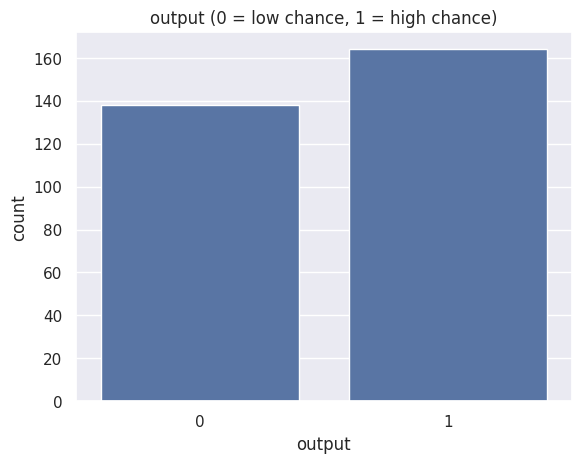

In [5]:
# the one duplicated row is removed
data = data.drop_duplicates()
print(data.shape)

sns.countplot(x='output', data=data)
plt.title('output (0 = low chance, 1 = high chance)')
plt.show()

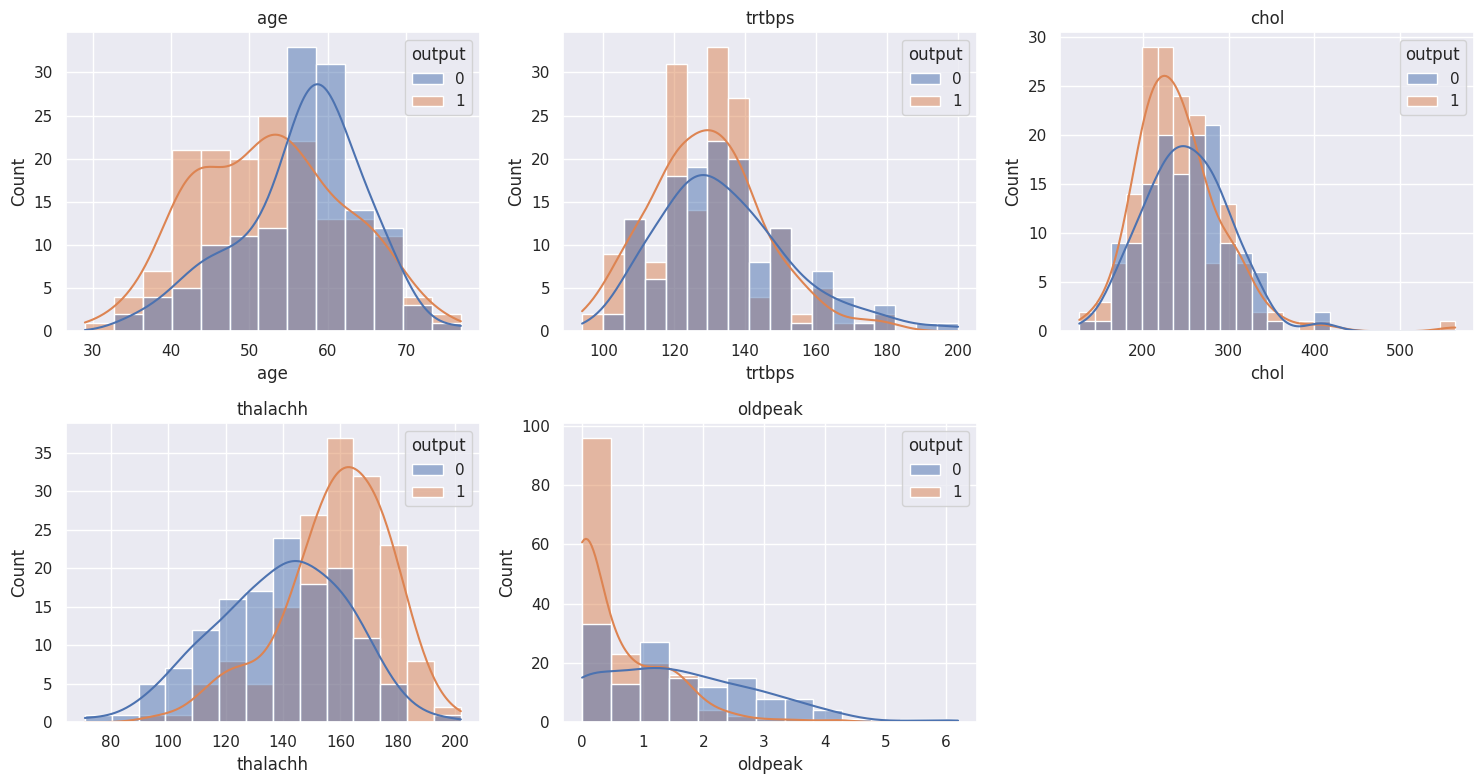

In [6]:
# numeric features
numeric = ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']

plt.figure(figsize=(15, 8))
for i in range(len(numeric)):
    plt.subplot(2, 3, i + 1)
    sns.histplot(data=data, x=numeric[i], hue='output', kde=True)
    plt.title(numeric[i])
plt.tight_layout()
plt.show()

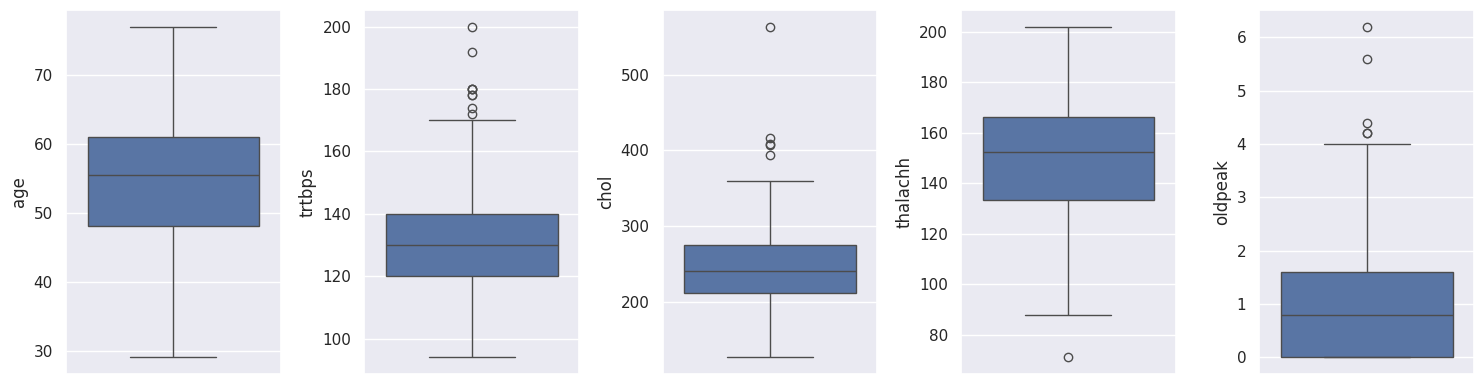

In [7]:
# boxplots to look for outliers
plt.figure(figsize=(15, 4))
for i in range(len(numeric)):
    plt.subplot(1, 5, i + 1)
    sns.boxplot(y=numeric[i], data=data)
plt.tight_layout()
plt.show()

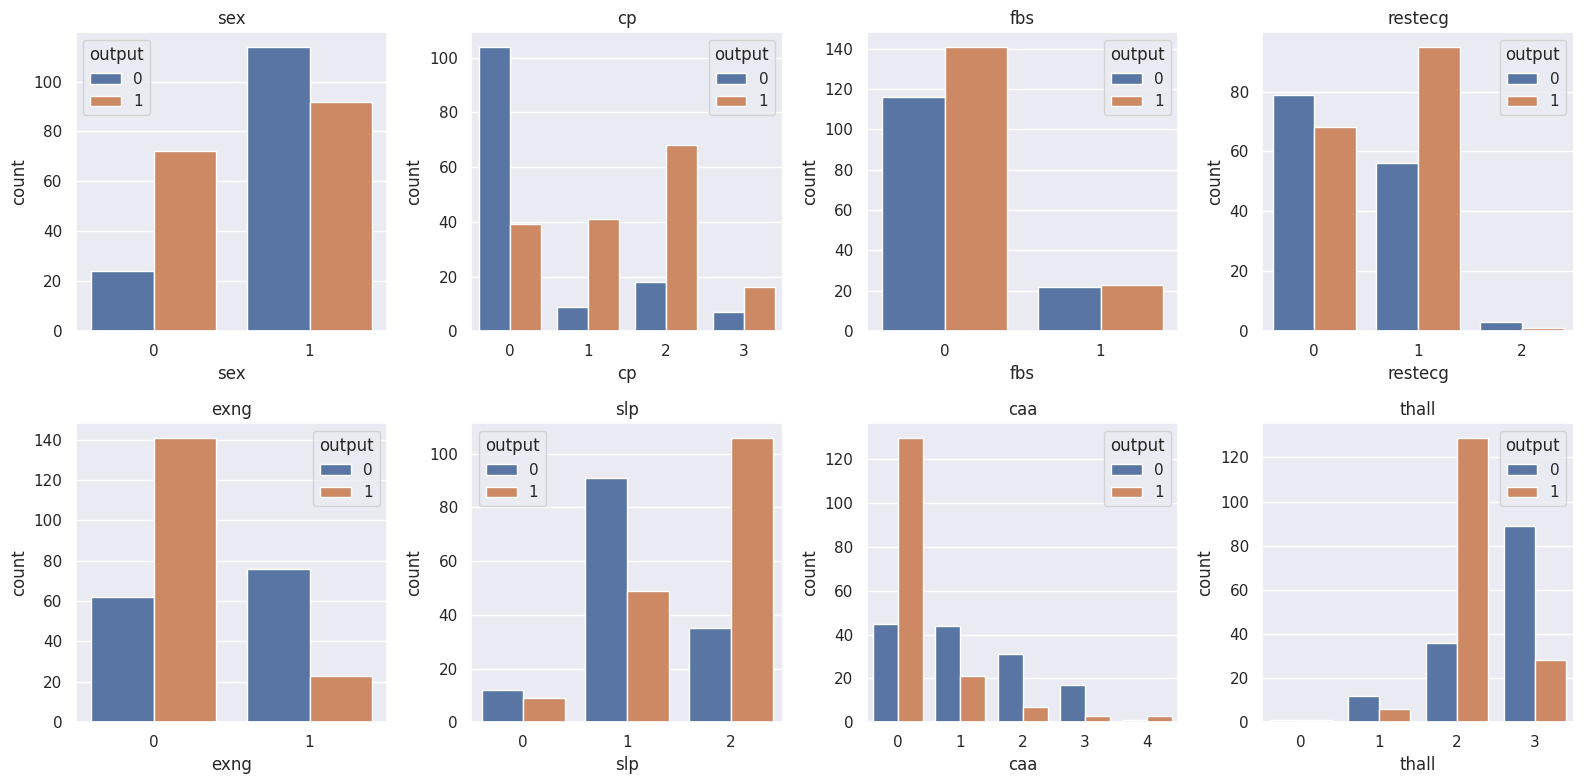

In [8]:
# categorical features
categorical = ['sex', 'cp', 'fbs', 'restecg', 'exng', 'slp', 'caa', 'thall']

plt.figure(figsize=(16, 8))
for i in range(len(categorical)):
    plt.subplot(2, 4, i + 1)
    sns.countplot(x=categorical[i], hue='output', data=data)
    plt.title(categorical[i])
plt.tight_layout()
plt.show()

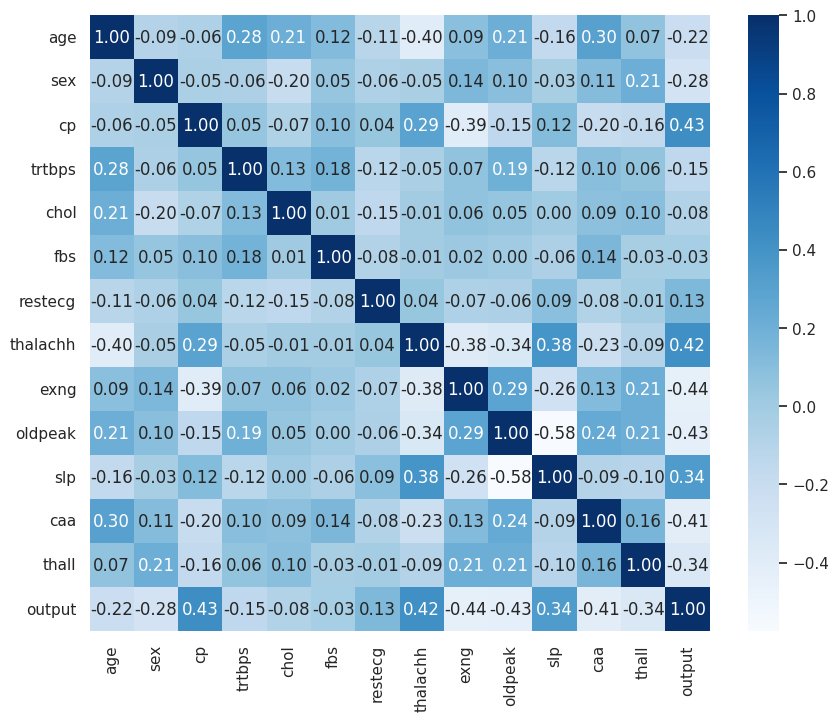

exng       -0.435601
oldpeak    -0.429146
caa        -0.408992
thall      -0.343101
sex        -0.283609
age        -0.221476
trtbps     -0.146269
chol       -0.081437
fbs        -0.026826
restecg     0.134874
slp         0.343940
thalachh    0.419955
cp          0.432080
output      1.000000
Name: output, dtype: float64


In [9]:
# correlation
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='Blues')
plt.show()

print(data.corr()['output'].sort_values())

## Data Preparation

In [10]:
X = data.drop('output', axis=1)
y = data['output']

print(X.shape, y.shape)

# standardize the features (x - mean) / std
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.head()

(302, 13) (302,)


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall
0,0.949794,0.682656,1.976470,0.764066,-0.261285,2.389793,-1.002541,0.018826,-0.698344,1.084022,-2.271182,-0.714911,-2.147955
1,-1.928548,0.682656,1.005911,-0.091401,0.067741,-0.418446,0.901657,1.636979,-0.698344,2.118926,-2.271182,-0.714911,-0.513994
2,-1.485726,-1.464866,0.035352,-0.091401,-0.822564,-0.418446,-1.002541,0.980971,-0.698344,0.307844,0.979514,-0.714911,-0.513994
3,0.174856,0.682656,0.035352,-0.661712,-0.203222,-0.418446,0.901657,1.243374,-0.698344,-0.209608,0.979514,-0.714911,-0.513994
4,0.285561,-1.464866,-0.935208,-0.661712,2.080602,-0.418446,0.901657,0.587366,1.431958,-0.382092,0.979514,-0.714911,-0.513994


## PCA

Variance explained: [0.213 0.119]


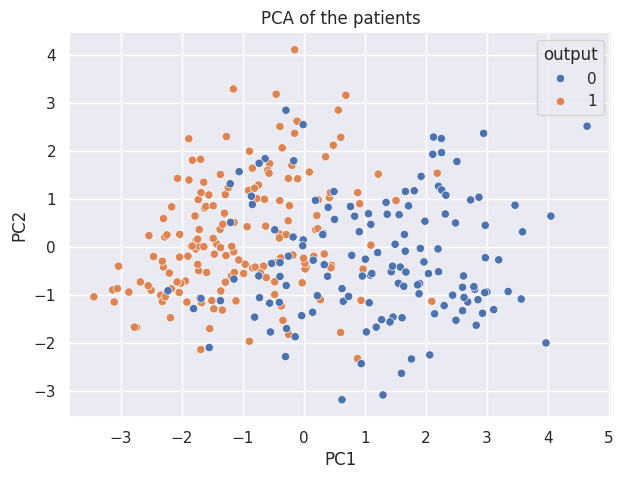

In [11]:
# reduce the 13 features to 2 components so we can plot the patients
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print('Variance explained:', pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of the patients')
plt.show()

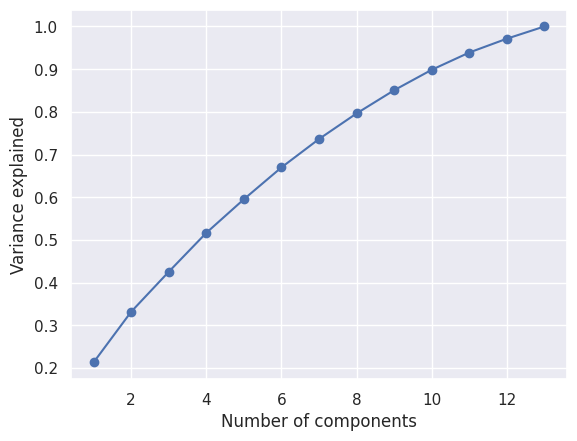

In [12]:
# how many components do we need?
pca_all = PCA()
pca_all.fit(X_scaled)

plt.plot(range(1, 14), np.cumsum(pca_all.explained_variance_ratio_), marker='o')
plt.xlabel('Number of components')
plt.ylabel('Variance explained')
plt.show()

## K-Means

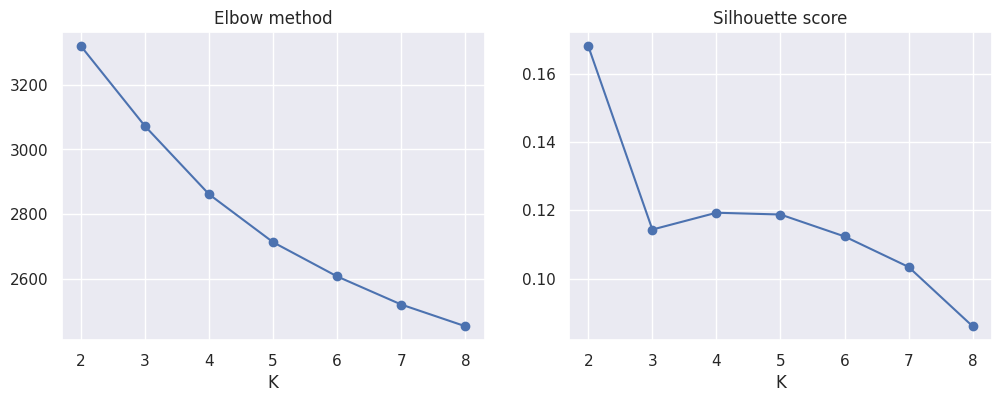

In [13]:
# elbow method and silhouette score to choose K
wcss = []
sil = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(2, 9), wcss, marker='o')
plt.title('Elbow method')
plt.xlabel('K')
plt.subplot(1, 2, 2)
plt.plot(range(2, 9), sil, marker='o')
plt.title('Silhouette score')
plt.xlabel('K')
plt.show()

output    0    1
cluster         
0        44  152
1        94   12


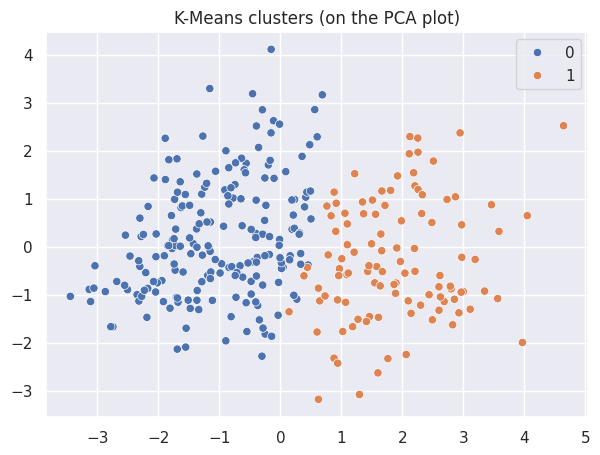

In [14]:
# K = 2 because the output has two classes
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# compare the clusters with the real output
print(pd.crosstab(clusters, y, rownames=['cluster'], colnames=['output']))

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters)
plt.title('K-Means clusters (on the PCA plot)')
plt.show()

## Modeling

### Cross validation

In [15]:
k_fold = KFold(n_splits=5, shuffle=True, random_state=42)

# KNN, Logistic Regression and SVM need scaled data, so they use a pipeline with StandardScaler
models = [
    ('KNN', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9))),
    ('Decision Tree', DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)),
    ('Random Forest', RandomForestClassifier(n_estimators=100, criterion='entropy', max_depth=5, random_state=42)),
    ('Naive Bayes', GaussianNB()),
    ('Logistic Regression', make_pipeline(StandardScaler(), LogisticRegression())),
    ('SVM', make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42))),
    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)),
    ('AdaBoost', AdaBoostClassifier(n_estimators=100, learning_rate=0.1)),
    ('XGBoost', XGBClassifier(max_depth=4, learning_rate=0.1, n_estimators=100, random_state=42)),
]

# voting model (hard voting)
model1 = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
model2 = XGBClassifier(max_depth=4, learning_rate=0.1, n_estimators=100, random_state=42)
model3 = RandomForestClassifier(n_estimators=100, criterion='entropy', max_depth=5, random_state=42)
voting = VotingClassifier(estimators=[('dt', model1), ('xgb', model2), ('rf', model3)], voting='hard')
models.append(('Voting', voting))

names = []
cv_scores = []

for name, model in models:
    score = cross_val_score(model, X, y, cv=k_fold, scoring='accuracy')
    result = round(np.mean(score) * 100, 2)
    names.append(name)
    cv_scores.append(result)
    print(name, ':', result)

KNN : 82.77
Decision Tree : 79.82


Random Forest : 83.43
Naive Bayes : 81.43
Logistic Regression : 82.45
SVM : 84.1


Gradient Boosting : 79.12


AdaBoost : 82.13


XGBoost : 80.13


Voting : 83.43


                 Model  Score
5                  SVM  84.10
2        Random Forest  83.43
9               Voting  83.43
0                  KNN  82.77
4  Logistic Regression  82.45
7             AdaBoost  82.13
3          Naive Bayes  81.43
8              XGBoost  80.13
1        Decision Tree  79.82
6    Gradient Boosting  79.12


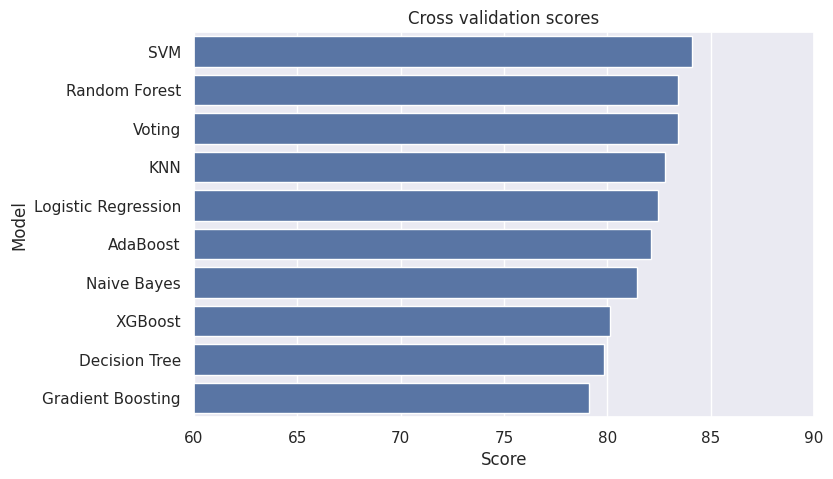

In [16]:
df_scores = pd.DataFrame({'Model': names, 'Score': cv_scores})
df_scores = df_scores.sort_values(by='Score', ascending=False)
print(df_scores)

plt.figure(figsize=(8, 5))
sns.barplot(x='Score', y='Model', data=df_scores)
plt.xlim(60, 90)
plt.title('Cross validation scores')
plt.show()

## Train Test Split

In [17]:
# 70% train, 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(X_train.shape, X_test.shape)

(211, 13) (91, 13)


In [18]:
models2 = [
    ('Logistic Regression', make_pipeline(StandardScaler(), LogisticRegression(random_state=42))),
    ('KNN', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))),
    ('Naive Bayes', GaussianNB()),
    ('SVM', make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42))),
    ('Decision Tree', DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)),
    ('Random Forest', RandomForestClassifier(n_estimators=100, max_depth=4, max_features=6, random_state=42)),
    ('XGBoost', XGBClassifier(max_depth=4, learning_rate=0.1, n_estimators=100, random_state=42)),
    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, max_features=6, random_state=42)),
    ('AdaBoost', AdaBoostClassifier(n_estimators=100, learning_rate=0.1)),
]

# voting model with 4 models
m1 = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
m2 = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, max_features=6, random_state=42)
m3 = XGBClassifier(max_depth=5, learning_rate=0.1, n_estimators=100, random_state=42)
m4 = RandomForestClassifier(n_estimators=100, criterion='entropy', max_depth=4, max_features=6, random_state=42)
v_clf = VotingClassifier(estimators=[('dt', m1), ('gb', m2), ('xgb', m3), ('rf', m4)], voting='hard')
models2.append(('Voting', v_clf))

test_names = []
train_acc = []
test_acc = []

for name, model in models2:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    test_names.append(name)
    train_acc.append(model.score(X_train, y_train) * 100)
    test_acc.append(accuracy_score(y_test, y_pred) * 100)

    print(name)
    print(confusion_matrix(y_test, y_pred))
    print('Train accuracy:', round(train_acc[-1], 2))
    print('Test accuracy:', round(test_acc[-1], 2))
    print(classification_report(y_test, y_pred))
    print('-' * 50)

Logistic Regression
[[34  8]
 [ 9 40]]
Train accuracy: 86.26
Test accuracy: 81.32
              precision    recall  f1-score   support

           0       0.79      0.81      0.80        42
           1       0.83      0.82      0.82        49

    accuracy                           0.81        91
   macro avg       0.81      0.81      0.81        91
weighted avg       0.81      0.81      0.81        91

--------------------------------------------------
KNN
[[35  7]
 [ 7 42]]
Train accuracy: 85.78
Test accuracy: 84.62
              precision    recall  f1-score   support

           0       0.83      0.83      0.83        42
           1       0.86      0.86      0.86        49

    accuracy                           0.85        91
   macro avg       0.85      0.85      0.85        91
weighted avg       0.85      0.85      0.85        91

--------------------------------------------------


Naive Bayes
[[37  5]
 [ 9 40]]
Train accuracy: 81.99
Test accuracy: 84.62
              precision    recall  f1-score   support

           0       0.80      0.88      0.84        42
           1       0.89      0.82      0.85        49

    accuracy                           0.85        91
   macro avg       0.85      0.85      0.85        91
weighted avg       0.85      0.85      0.85        91

--------------------------------------------------


SVM
[[34  8]
 [ 9 40]]
Train accuracy: 91.94
Test accuracy: 81.32
              precision    recall  f1-score   support

           0       0.79      0.81      0.80        42
           1       0.83      0.82      0.82        49

    accuracy                           0.81        91
   macro avg       0.81      0.81      0.81        91
weighted avg       0.81      0.81      0.81        91

--------------------------------------------------
Decision Tree
[[33  9]
 [13 36]]
Train accuracy: 87.2
Test accuracy: 75.82
              precision    recall  f1-score   support

           0       0.72      0.79      0.75        42
           1       0.80      0.73      0.77        49

    accuracy                           0.76        91
   macro avg       0.76      0.76      0.76        91
weighted avg       0.76      0.76      0.76        91

--------------------------------------------------


Random Forest
[[33  9]
 [ 7 42]]
Train accuracy: 92.89
Test accuracy: 82.42


              precision    recall  f1-score   support

           0       0.82      0.79      0.80        42
           1       0.82      0.86      0.84        49

    accuracy                           0.82        91
   macro avg       0.82      0.82      0.82        91
weighted avg       0.82      0.82      0.82        91

--------------------------------------------------


XGBoost
[[34  8]
 [10 39]]
Train accuracy: 100.0
Test accuracy: 80.22
              precision    recall  f1-score   support

           0       0.77      0.81      0.79        42
           1       0.83      0.80      0.81        49

    accuracy                           0.80        91
   macro avg       0.80      0.80      0.80        91
weighted avg       0.80      0.80      0.80        91

--------------------------------------------------


Gradient Boosting
[[35  7]
 [10 39]]
Train accuracy: 100.0
Test accuracy: 81.32
              precision    recall  f1-score   support

           0       0.78      0.83      0.80        42
           1       0.85      0.80      0.82        49

    accuracy                           0.81        91
   macro avg       0.81      0.81      0.81        91
weighted avg       0.82      0.81      0.81        91

--------------------------------------------------


AdaBoost
[[35  7]
 [ 6 43]]
Train accuracy: 85.78
Test accuracy: 85.71
              precision    recall  f1-score   support

           0       0.85      0.83      0.84        42
           1       0.86      0.88      0.87        49

    accuracy                           0.86        91
   macro avg       0.86      0.86      0.86        91
weighted avg       0.86      0.86      0.86        91

--------------------------------------------------


Voting
[[36  6]
 [ 9 40]]
Train accuracy: 98.1
Test accuracy: 83.52
              precision    recall  f1-score   support

           0       0.80      0.86      0.83        42
           1       0.87      0.82      0.84        49

    accuracy                           0.84        91
   macro avg       0.83      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91

--------------------------------------------------


                 Model       Train       Test
8             AdaBoost   85.781991  85.714286
1                  KNN   85.781991  84.615385
2          Naive Bayes   81.990521  84.615385
9               Voting   98.104265  83.516484
5        Random Forest   92.890995  82.417582
0  Logistic Regression   86.255924  81.318681
7    Gradient Boosting  100.000000  81.318681
3                  SVM   91.943128  81.318681
6              XGBoost  100.000000  80.219780
4        Decision Tree   87.203791  75.824176


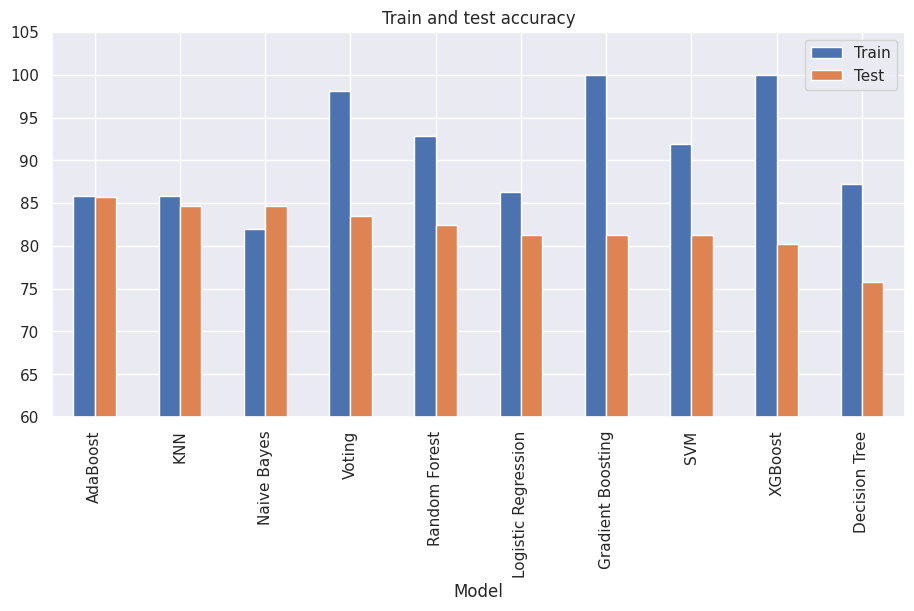

In [19]:
results = pd.DataFrame({'Model': test_names, 'Train': train_acc, 'Test': test_acc})
results = results.sort_values(by='Test', ascending=False)
print(results)

results.set_index('Model').plot(kind='bar', figsize=(11, 5))
plt.ylim(60, 105)
plt.title('Train and test accuracy')
plt.show()